План работы:
Первичный осмотр данных — shape, dtypes, head, describe
Анализ пропусков — сколько, где, гипотезы почему, стратегия обработки
Анализ дубликатов и аномалий — выбросы в Age/Fare, странные значения
Univariate-анализ числовых переменных — распределения Age, Fare
Univariate-анализ категориальных переменных — Sex, Pclass, Embarked
Bivariate-анализ: признаки vs Survived — содержательная часть
Корреляционный анализ — heatmap, мультиколлинеарность
Multivariate-паттерны — Pclass + Sex + Survived вместе
Формулирование гипотез/выводов — что влияет на выживаемость и почему
summary.

In [26]:
import pandas as pd 
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

df = sns.load_dataset('titanic')


Пункт 1. Первичный осмотр данных:

In [2]:
print(df.shape)
df.head()


(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
df.describe(include=['object', 'category'])

C:\Users\danil\AppData\Local\Temp\ipykernel_24008\3718493387.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['object', 'category'])


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


Пункт 2. Анализ пропусков:

In [5]:
miss_count = df.isnull().sum()
miss_perc = (miss_count * 100)/len(df)
miss_df = pd.DataFrame({"Количество пропусков":miss_count,
                        "Процент пропусков":miss_perc})
mask = miss_df["Количество пропусков"] > 0
miss_df = miss_df[mask].sort_values(by="Процент пропусков", ascending=False)
print(miss_df)


             Количество пропусков  Процент пропусков
deck                          688          77.216611
age                           177          19.865320
embarked                        2           0.224467
embark_town                     2           0.224467


Визуализация пропусков:

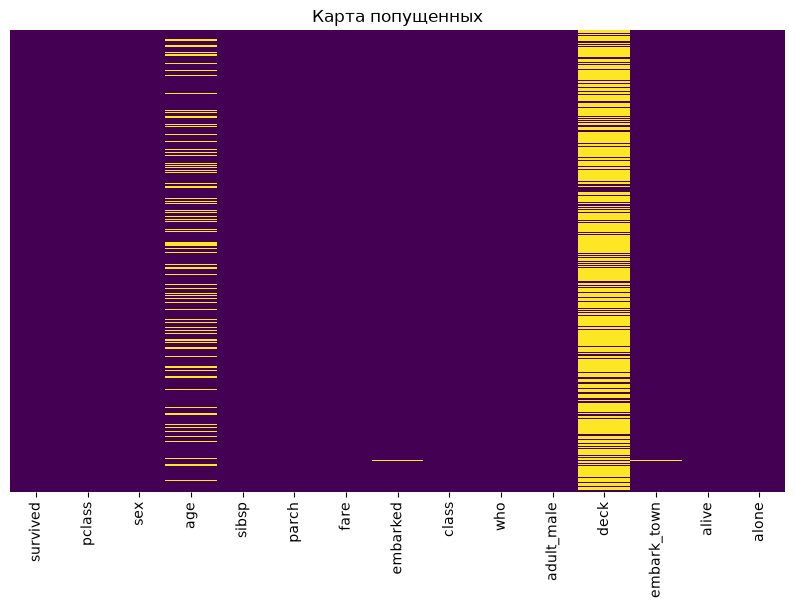

In [6]:
plt.figure(figsize=(10,6))

sns.heatmap(df.isnull(), cbar=False, yticklabels = False,  cmap='viridis')

plt.title("Карта попущенных")
plt.show()

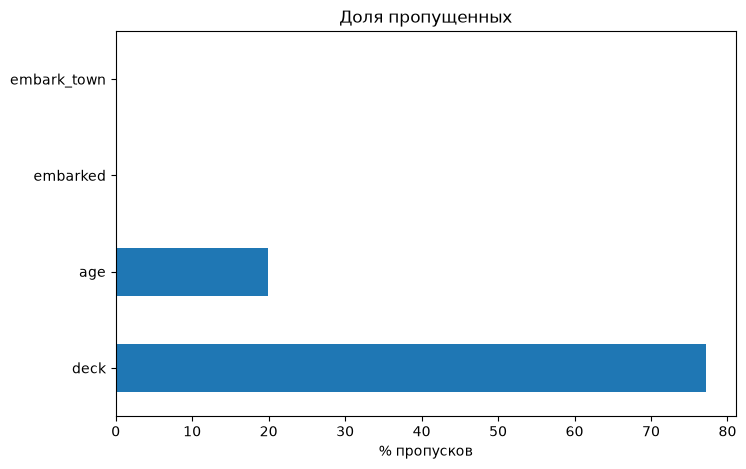

In [7]:
plt.figure(figsize=(8, 5))
miss_df['Процент пропусков'].plot(kind='barh')
plt.xlabel('% пропусков')
plt.title('Доля пропущенных')

plt.show()

Гипотеза - пропускм в deck не случайны. 
Логично предположить, что палубу (deck) чаще фиксировали для пассажиров с каютами (то есть более высокого класса).

In [8]:
df["miss_d"] = df["deck"].isnull()

print(df.groupby("pclass")["miss_d"].mean())


pclass
1    0.189815
2    0.913043
3    0.975560
Name: miss_d, dtype: float64


Корректировка:

In [9]:

df['age_m'] = df['age'].fillna(df['age'].median()) #создам новую колонку, чтобы сохранить оригинал  для стат. проверки гипотезы в пункте 9!
df['FamilySize'] = df['sibsp'] + df['parch'] + 1
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

print(df.isnull().sum())

df = df.drop(columns=['alive', 'class', 'embark_town', 'adult_male', 'deck', 'miss_d'])
print(df.columns.tolist())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      0
alive            0
alone            0
miss_d           0
age_m            0
FamilySize       0
dtype: int64
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'who', 'alone', 'age_m', 'FamilySize']


Пункт 3: Дубликаты и выбросы (аномалии)
Случайное совпадение всех значений у разных пассажиров статистически вероятно.

Количество полных дубликатов: 111


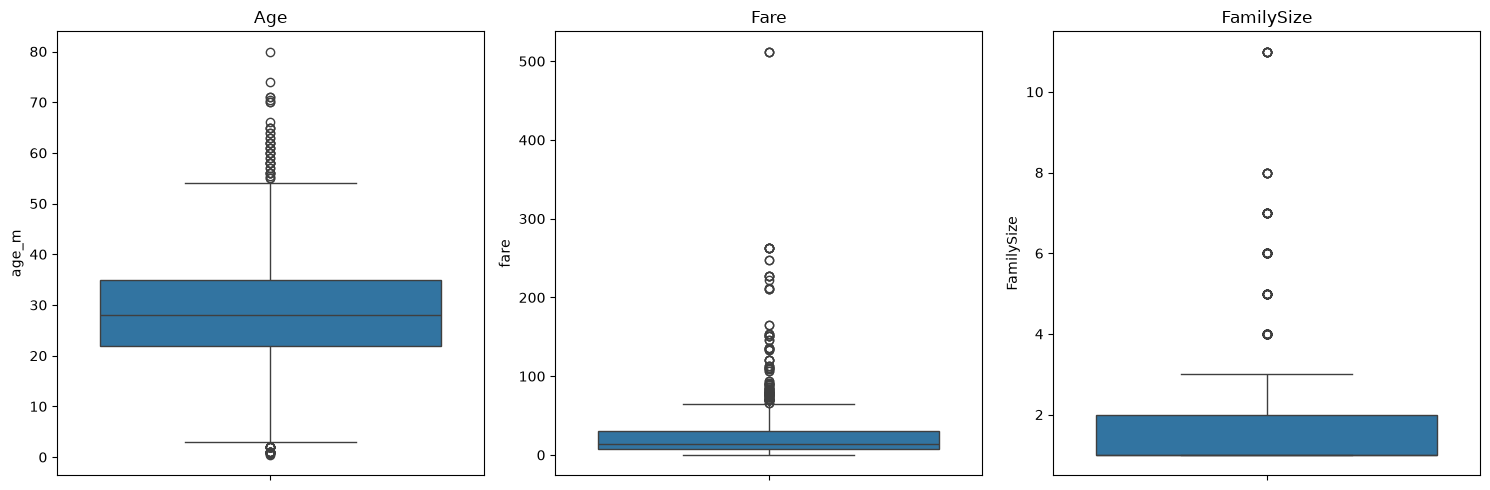

In [10]:
print(f"Количество полных дубликатов: {df.duplicated().sum()}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(y=df['age_m'], ax=axes[0])
axes[0].set_title('Age')

sns.boxplot(y=df['fare'], ax=axes[1])
axes[1].set_title('Fare')

sns.boxplot(y=df['FamilySize'], ax=axes[2])
axes[2].set_title('FamilySize')

plt.tight_layout()
plt.show()

Численный подсчёт выбросов через правило IQR:

In [11]:
def count_outliers_iqr(column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return len(outliers), lower_bound, upper_bound

for col in ['age_m', 'fare', 'sibsp', 'parch', 'FamilySize']:
    count, low, up = count_outliers_iqr(col)
    print(f"{col}: {count} выбросов (границы: {low:.2f} — {up:.2f})")


age_m: 66 выбросов (границы: 2.50 — 54.50)
fare: 116 выбросов (границы: -26.72 — 65.63)
sibsp: 46 выбросов (границы: -1.50 — 2.50)
parch: 213 выбросов (границы: 0.00 — 0.00)
FamilySize: 91 выбросов (границы: -0.50 — 3.50)


Признаки sibsp, parch и FamilySize сильно дискретны, поэтому правило IQR формально помечает как выбросы значения, которые на деле являются нормальной вариативностью (пассажир не один на борту). Особенно показателен parch — границы IQR (0.00–0.00) означают любое ненулевое значение считается выбросом, хотя иметь 1-2 родителей/детей — обычная ситуация. Признаки age_m и fare содержат более осмысленные выбросы (пожилые/очень дорогие билеты), но они не являются ошибками ввода данных, поэтому ни один выброс не удаляется — они несут содержательную информацию.

Пункт 4: Univariate-анализ числовых переменных
Гистограммы + KDE (кривая плотности)

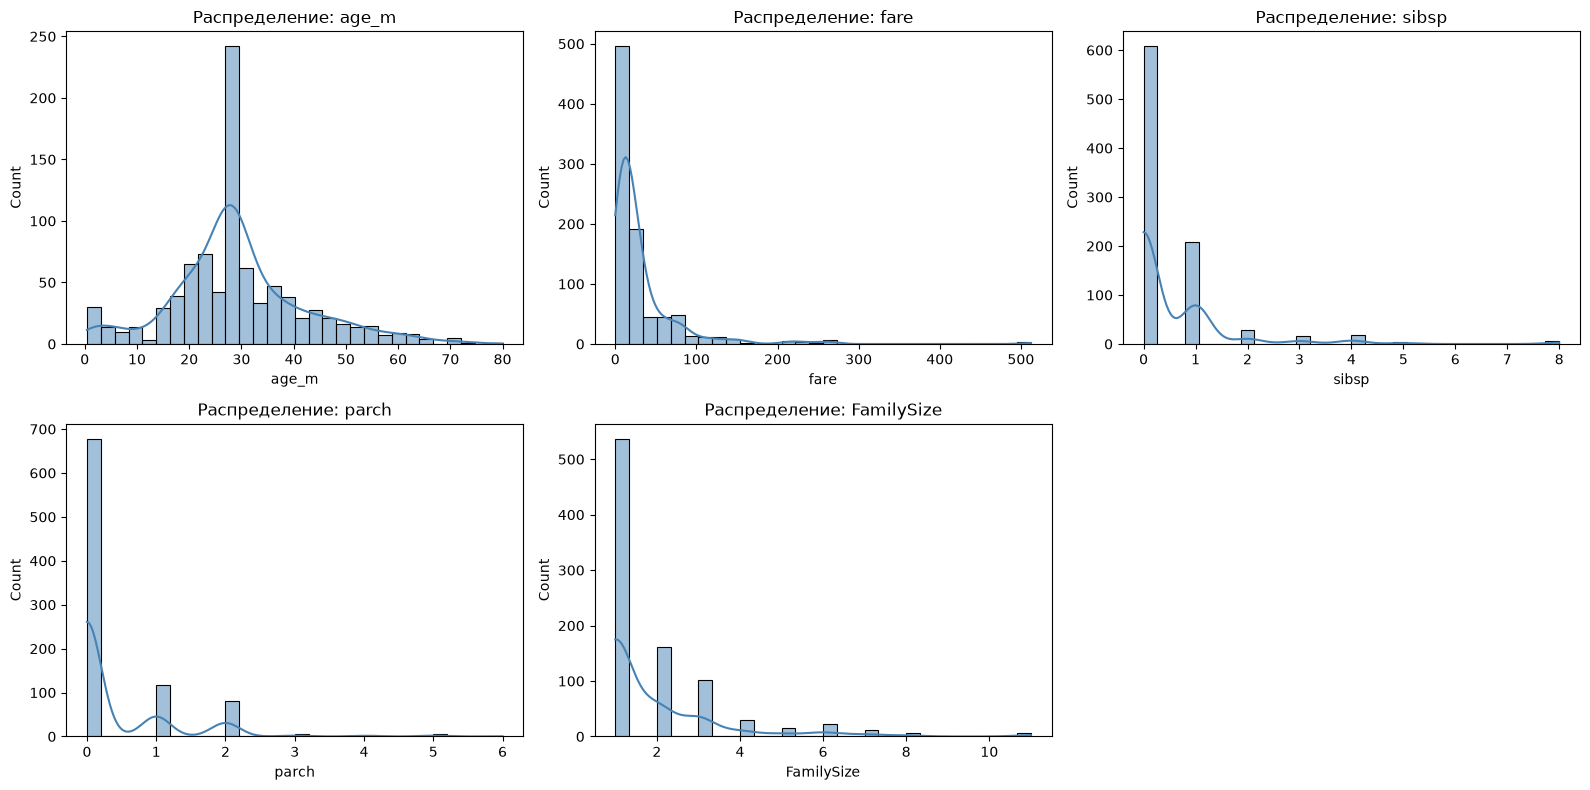

In [12]:
numeric_cols = ['age_m', 'fare', 'sibsp', 'parch', 'FamilySize']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=30, color='steelblue')
    axes[i].set_title(f'Распределение: {col}')

fig.delaxes(axes[5]) 
plt.tight_layout()
plt.show()

In [13]:
#Числовая проверка асимметрии и эксцесса
from scipy.stats import skew, kurtosis

for col in numeric_cols:
    print(f"{col}: skewness = {df[col].skew():.2f}, kurtosis = {df[col].kurtosis():.2f}")

age_m: skewness = 0.51, kurtosis = 0.99
fare: skewness = 4.79, kurtosis = 33.40
sibsp: skewness = 3.70, kurtosis = 17.88
parch: skewness = 2.75, kurtosis = 9.78
FamilySize: skewness = 2.73, kurtosis = 9.16


fare — самый проблемный признак (skew 4.79, kurtosis 33.4 — это АНОМАЛЬНО высокие значения, у нормального распределения kurtosis ≈ 0)

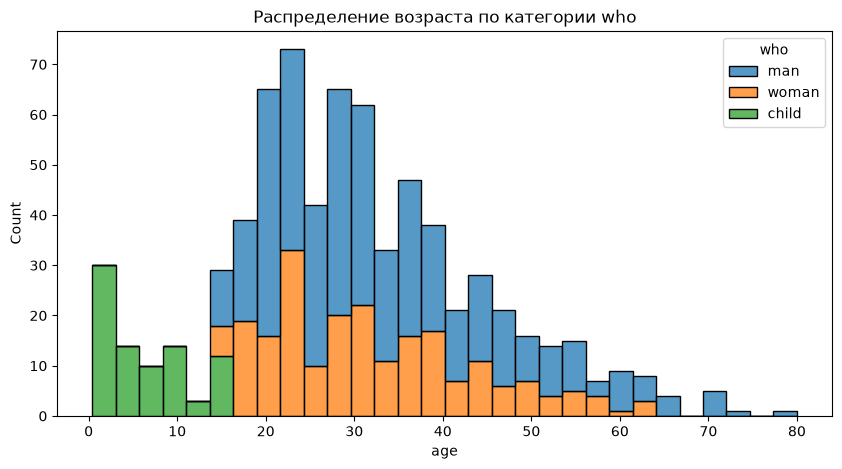

In [14]:
#распределение age с разбивкой по who
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='age', hue='who', multiple='stack', bins=30)
plt.title('Распределение возраста по категории who')
plt.show()

Пункт 5: Univariate — категориальные переменные

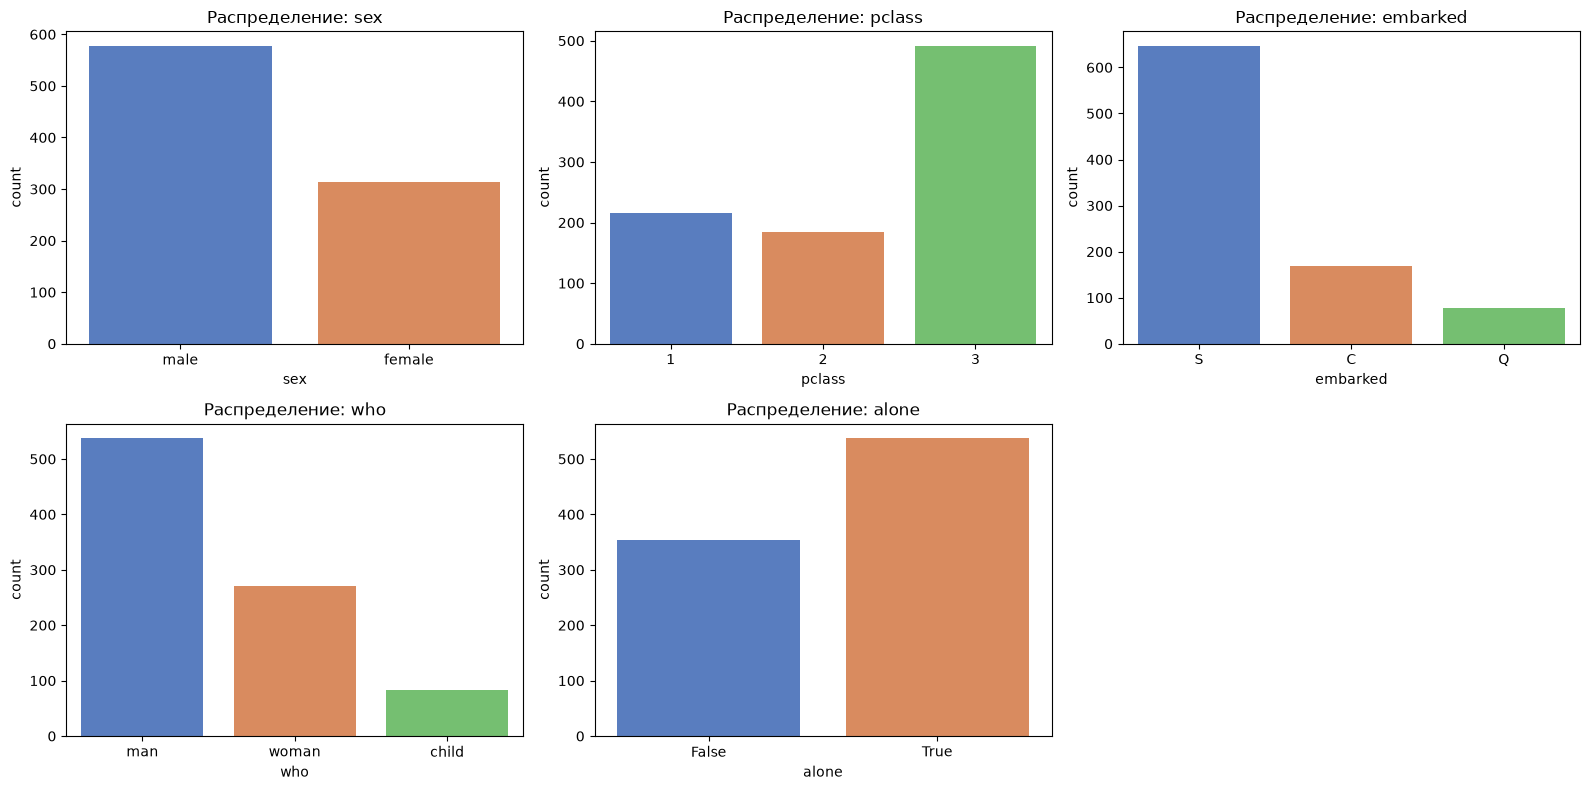

In [15]:
cat_cols = ['sex', 'pclass', 'embarked', 'who', 'alone']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue=col, legend=False, ax=axes[i], palette='muted')
    axes[i].set_title(f'Распределение: {col}')

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

Пункт 6: Bivariate — признаки vs survived

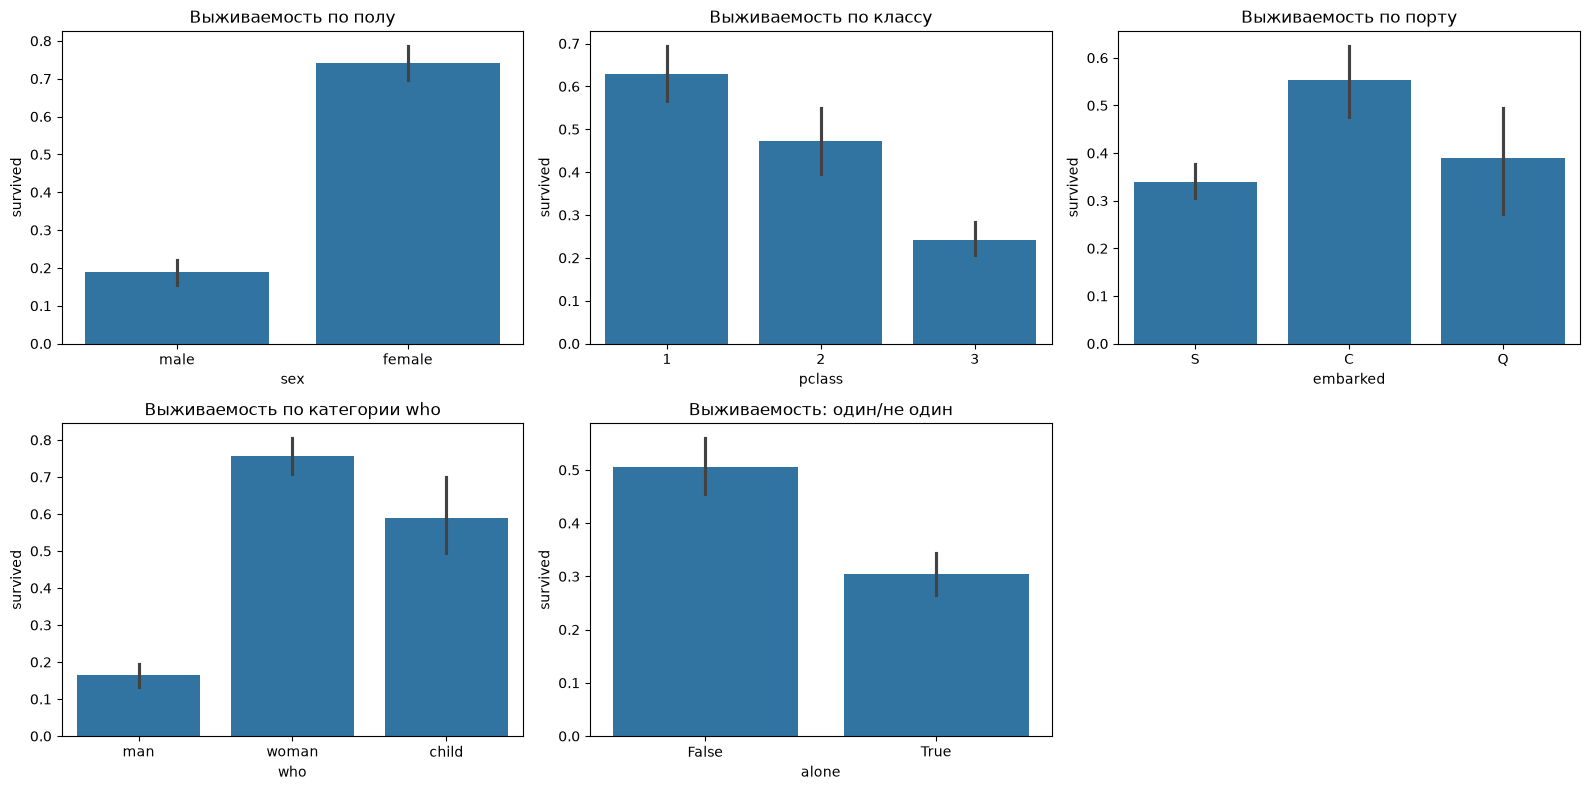

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

sns.barplot(data=df, x='sex', y='survived', ax=axes[0])
axes[0].set_title('Выживаемость по полу')

sns.barplot(data=df, x='pclass', y='survived', ax=axes[1])
axes[1].set_title('Выживаемость по классу')

sns.barplot(data=df, x='embarked', y='survived', ax=axes[2])
axes[2].set_title('Выживаемость по порту')

sns.barplot(data=df, x='who', y='survived', ax=axes[3])
axes[3].set_title('Выживаемость по категории who')

sns.barplot(data=df, x='alone', y='survived', ax=axes[4])
axes[4].set_title('Выживаемость: один/не один')

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

Выживаемость женщин ≈74%, мужчин ≈19% (разница более чем в 3.5 раза). Класс каюты показывает чёткий градиент: 1 класс ≈63%, 2 класс ≈47%, 3 класс ≈24%. По категории who видно, что выживаемость женщин (≈76%) и детей (≈59%) заметно выше, чем взрослых мужчин (≈16%). Пассажиры не одни (с семьёй) выживали чаще (≈51%), чем одиночки (≈30%).

числовые признаки vs survived:
По boxplot видно, что age почти не различается между выжившими и погибшими (медиана ≈28 в обеих группах), а вот fare у выживших заметно выше — медиана и межквартильный размах смещены вверх.

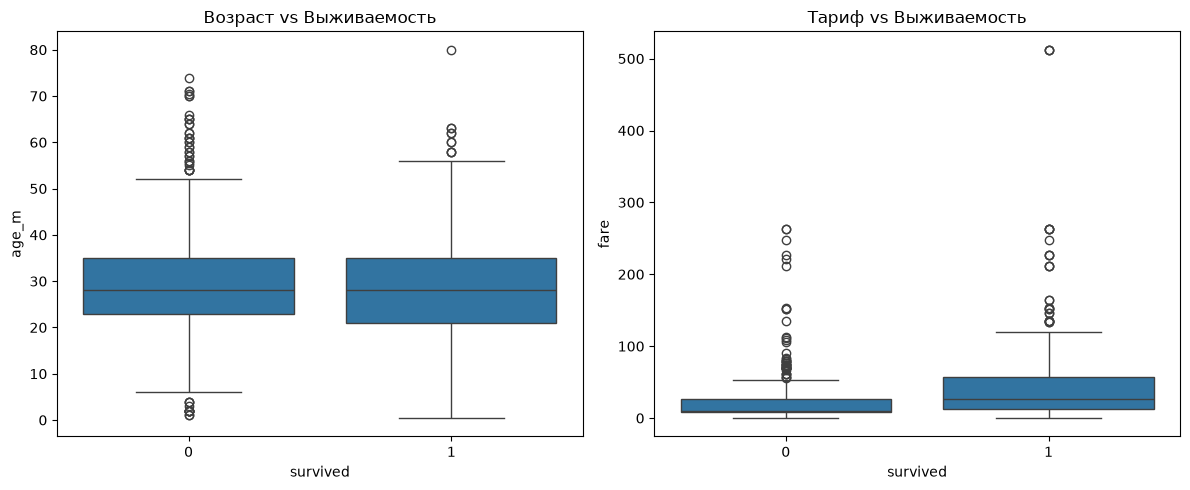

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x='survived', y='age_m', ax=axes[0])
axes[0].set_title('Возраст vs Выживаемость')

sns.boxplot(data=df, x='survived', y='fare', ax=axes[1])
axes[1].set_title('Тариф vs Выживаемость')

plt.tight_layout()
plt.show()

Пункт 7: Корреляционный анализ

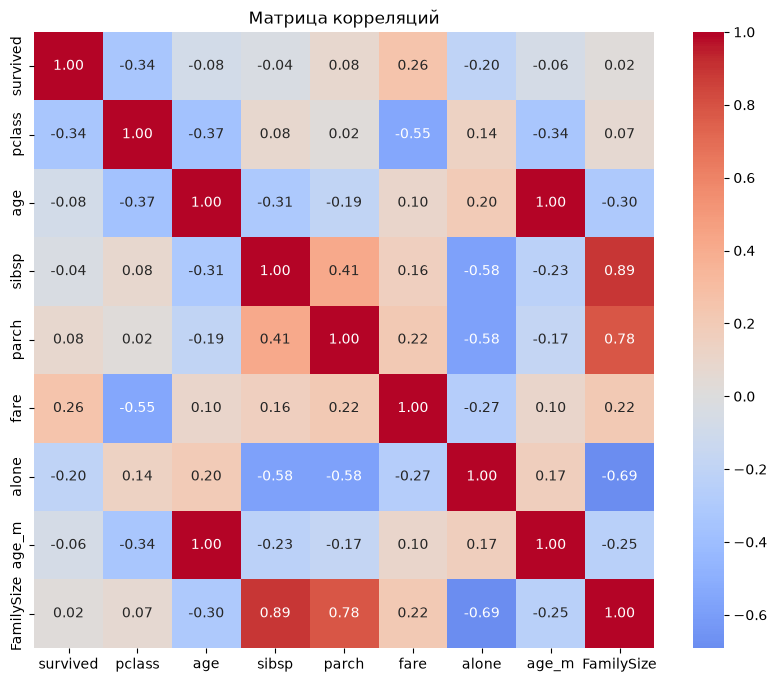

In [18]:
plt.figure(figsize=(10, 8))
corr = df.select_dtypes(include=[np.number, 'bool']).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Матрица корреляций')
plt.show()

Сильнее всего с survived коррелирует pclass (-0.34) и fare (+0.26) — что логично согласуется с bivariate-анализом. Обнаружена выраженная мультиколлинеарность между sibsp, parch, FamilySize и alone (например, sibsp–FamilySize = 0.89, parch–FamilySize = 0.78, alone–FamilySize = -0.69) — это ожидаемо, так как FamilySize построен из sibsp и parch.

Пункт 8: Multivariate — комбинации признаков

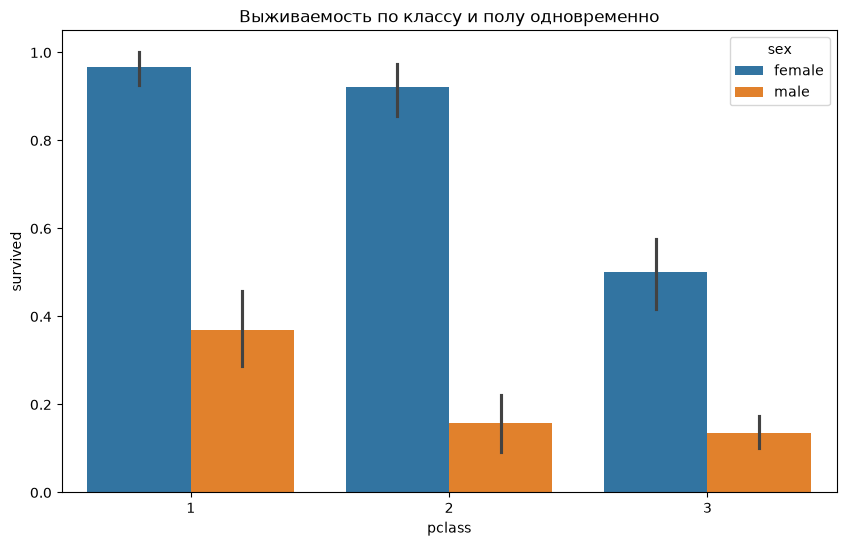

In [19]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='pclass', y='survived', hue='sex')
plt.title('Выживаемость по классу и полу одновременно')
plt.show()

Комбинация класса и пола показывает наиболее выраженный эффект: женщины 1 и 2 класса выживали почти всегда (≈97% и ≈92%), тогда как мужчины 3 класса — реже всех (≈14%). Это показывает, что пол и класс действуют не независимо, а усиливают друг друга — женщина 3 класса (≈50%) выживала чаще, чем мужчина 1 класса (≈37%), то есть пол оказывается более сильным фактором, чем класс, но оба вместе дают наиболее контрастную картину.

Пункт 9: Статистическая проверка гипотез

Гипотеза 1: Выживаемость зависит от пола
H₀: пол и выживаемость независимы
H₁: пол влияет на выживаемость

Пол и survived — оба категориальные → хи-квадрат.

In [20]:
from scipy import stats

contingency_sex = pd.crosstab(df['sex'], df['survived'])
print(contingency_sex)

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_sex)
print(f"\nChi2 = {chi2:.2f}, p-value = {p_value:.10f}, dof = {dof}")

print(expected)

# Размер эффекта - Cramers v (насколько сильна связь?)
n = contingency_sex.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency_sex.shape) - 1)))
print(f"Cramers v = {cramers_v:.3f}")


survived    0    1
sex               
female     81  233
male      468  109

Chi2 = 260.72, p-value = 0.0000000000, dof = 1
[[193.47474747 120.52525253]
 [355.52525253 221.47474747]]
Cramers v = 0.541


Результат: χ² = 260.72, p-value ≈ 0 (< 0.001), Cramér's V = 0.541.
Вывод: p-value значительно меньше 0.05 → H₀ отвергается. Пол статистически значимо связан с выживаемостью. Более того, Cramér's V = 0.541 говорит о сильной практической связи (не только статистически значимой, но и содержательно важной) — это самый сильный из всех проверенных факторов.

Гипотеза 2: Выживаемость зависит от класса

H₀: класс и выживаемость независимы
H₁: класс влияет на выживаемость

In [21]:
contingency_class = pd.crosstab(df['pclass'], df['survived'])
print(contingency_class)

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_class)
print(f"\nChi2 = {chi2:.2f}, p-value = {p_value:.10f}, dof = {dof}")

n = contingency_class.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency_class.shape) - 1)))
print(f"Cramér's V = {cramers_v:.3f}")

survived    0    1
pclass            
1          80  136
2          97   87
3         372  119

Chi2 = 102.89, p-value = 0.0000000000, dof = 2
Cramér's V = 0.340


Результат: χ² = 102.89, p-value ≈ 0, Cramér's V = 0.340.
Вывод: H₀ отвергается — класс статистически значимо влияет на выживаемость. Связь умеренная (0.340), слабее, чем у пола, но всё ещё существенная.

Гипотеза 3: Возраст выживших и погибших отличается

H₀: средний возраст выживших = среднему возрасту погибших
H₁: средний возраст отличается

Сначала проверим нормальность распределения age в каждой группе — это определит, какой тест использовать:

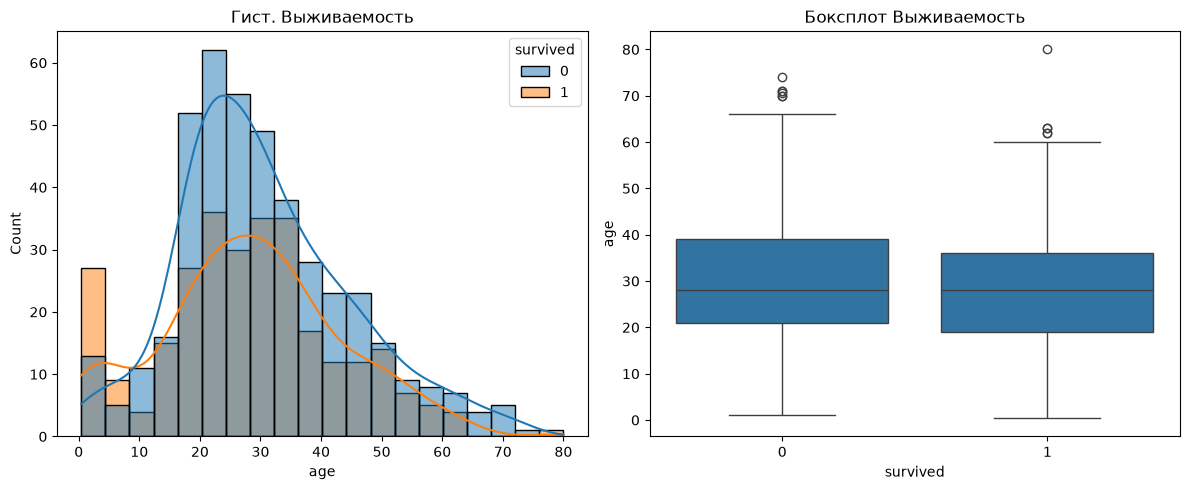

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


sns.histplot(
    data=df,
    x='age',
    hue='survived',
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Гист. Выживаемость')

sns.boxplot(data=df, x='survived', y='age', ax=axes[1])
axes[1].set_title('Боксплот Выживаемость')

plt.tight_layout()
plt.show()


In [23]:
survived_age = df[df['survived'] == 1]['age'].dropna()
died_age = df[df['survived'] == 0]['age'].dropna()

# Тест Шапиро-Уилка на нормальность (H0: распределение нормальное)
print("Shapiro-Wilk для выживших:", stats.shapiro(survived_age))
print("Shapiro-Wilk для погибших:", stats.shapiro(died_age))


Shapiro-Wilk для выживших: ShapiroResult(statistic=np.float64(0.9827258203228207), pvalue=np.float64(0.0014264514374719827))
Shapiro-Wilk для погибших: ShapiroResult(statistic=np.float64(0.9689364577284161), pvalue=np.float64(7.81552733877256e-08))


In [24]:
stat, p_value = stats.mannwhitneyu(survived_age, died_age, alternative='two-sided')
print(f"Mann-Whitney U: statistic = {stat:.2f}, p-value = {p_value:.4f}")

print(f"\nСредний возраст выживших: {survived_age.mean():.2f}")
print(f"Средний возраст погибших: {died_age.mean():.2f}")

Mann-Whitney U: statistic = 57682.00, p-value = 0.1605

Средний возраст выживших: 28.34
Средний возраст погибших: 30.63


Результат: тест Шапиро-Уилка показал p < 0.05 в обеих группах - распределение возраста не нормальное, поэтому применён непараметрический тест Манна-Уитни. Mann-Whitney U: p-value = 0.1605.
Вывод: p-value больше 0.05 → H₀ не отвергается. Статистически значимой разницы в возрасте между выжившими (в среднем 28.34 года) и погибшими (30.63 года) нет — несмотря на видимую разницу в 2.3 года, она укладывается в рамки случайной вариации выборки.

Гипотеза 4: Тариф выживших и погибших отличается

In [25]:
survived_fare = df[df['survived'] == 1]['fare']
died_fare = df[df['survived'] == 0]['fare']

# fare сильно skewed (skew=4.79), поэтому сразу берём непараметрический тест
stat, p_value = stats.mannwhitneyu(survived_fare, died_fare, alternative='two-sided')
print(f"Mann-Whitney U: statistic = {stat:.2f}, p-value = {p_value:.10f}")

print(f"\nМедианный тариф выживших: {survived_fare.median():.2f}")
print(f"Медианный тариф погибших: {died_fare.median():.2f}")

Mann-Whitney U: statistic = 129951.50, p-value = 0.0000000000

Медианный тариф выживших: 26.00
Медианный тариф погибших: 10.50


Результат: Mann-Whitney U, p-value ≈ 0 (< 0.001). Медианный тариф выживших — 26.0, погибших — 10.5 (более чем в 2 раза выше).
Вывод: H₀ отвергается — разница в тарифе между выжившими и погибшими статистически значима и практически заметна (в 2.5 раза по медиане).

## Итоговые выводы EDA

1. **Пол — главный предиктор выживаемости**: женщины выживали в ~74% случаев против ~19% у мужчин.
2. **Класс имеет чёткий градиент влияния**: 63% (1 класс) → 47% (2 класс) → 24% (3 класс).
3. **Комбинация пол+класс усиливает эффект**: женщины 1-2 класса выживали почти всегда (92–97%), мужчины 3 класса — реже всего (14%).
4. **Возраст сам по себе слабо влияет на выживание** (корреляция -0.06), но категория "child" внутри `who` выживала чаще взрослых мужчин — важен не возраст напрямую, а социальная роль.
5. **Fare коррелирует с выживанием (+0.26)**, что фактически отражает влияние класса — более дорогой билет = более высокий класс = выше шанс выжить.
6. **Пропуски не случайны**: пропуски в deck напрямую связаны с pclass (77–97.5% для 2-3 класса против 19% для 1 класса) — типичный пример MAR.
7. **Выбросы в данных — не ошибки**: сильная асимметрия fare (skew=4.79), sibsp, parch отражают реальную неоднородность пассажиров (богатые/бедные, одиночки/большие семьи), поэтому не удалялись.
8. **Обнаружена мультиколлинеарность** между FamilySize и его компонентами (sibsp, parch, alone) — важно учитывать при дальнейшем моделировании.
### Статистическая проверка гипотез
1. **Пол → survived**: χ²=260.72, p≈0, Cramér's V=0.541 (сильная связь) — H₀ отвергается.
2. **Класс → survived**: χ²=102.89, p≈0, Cramér's V=0.340 (умеренная связь) — H₀ отвергается.
3. **Возраст выживших vs погибших**: Mann-Whitney p=0.1605 — H₀ НЕ отвергается, статистически значимой разницы в возрасте нет (28.3 vs 30.6 лет — разница в пределах случайности).
4. **Тариф выживших vs погибших**: Mann-Whitney p≈0 — H₀ отвергается, медианы 26.0 vs 10.5 значимо различаются.
